16-7-26
Thursday
Day-17

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

import os
import warnings
warnings.filterwarnings('ignore') # hides unnecessary warning messages

sns.set_theme(style='whitegrid',palette='muted')
plt.rcParams['figure.dpi']=110
plt.rcParams['figure.figsize']=(10,6)

In [2]:
df=pd.read_csv('Mall_Customers.csv')
print("Successfully loaded from loacal dictonary!")
df.head()

Successfully loaded from loacal dictonary!


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Clustering:grouping of similar data without any specific name
1. make a scatter plot : 
2. to know the value of k (no. groups)
3. centroids and distance between centoids and every point and make groups
4. shift the centroid to their position and again calculate the distances this keeps on repeating till the centroid stops moving


In [3]:
df.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')

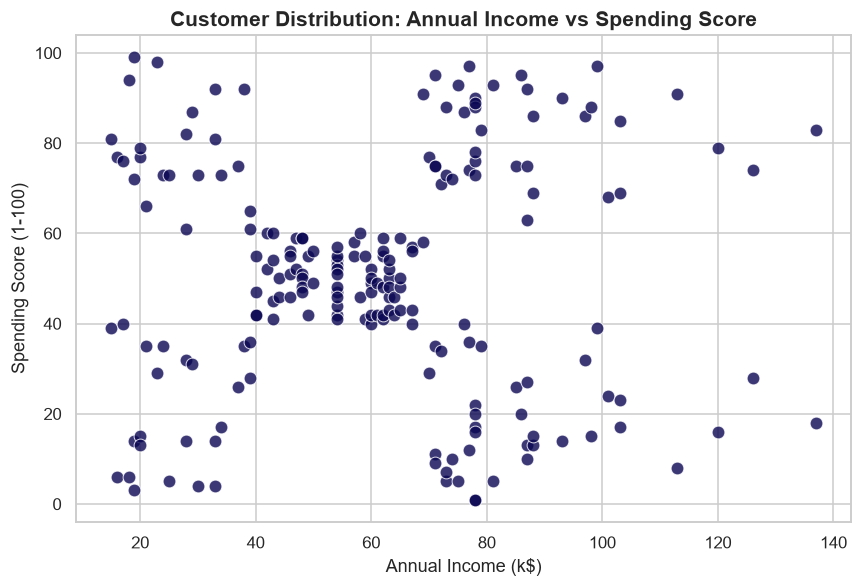

In [4]:
# will do scaling 
plt.figure(figsize=(8,5.5))
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    s=70,
    color='#0a0653',alpha=0.8
)
plt.title('Customer Distribution: Annual Income vs Spending Score',fontsize=14,fontweight='bold')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.tight_layout()
plt.show()

In [5]:
x=df[['Annual Income (k$)','Spending Score (1-100)']]
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)
x_scaled_df=pd.DataFrame(x_scaled,columns=x.columns)
print("=== First 5 rows of SCALED features ===")
display(x_scaled_df.head())

=== First 5 rows of SCALED features ===


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


In [6]:
kmeans=KMeans(n_clusters=5,init='k-means++',n_init=10,random_state=42)
kmeans.fit(x_scaled)
labels=kmeans.labels_
centroids_scaled=kmeans.cluster_centers_
print("Model training complete!")
print(f"First 10 customers are assigned to these clusters")

Model training complete!
First 10 customers are assigned to these clusters


In [7]:
df


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


[[55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [26.30434783 20.91304348]]


Text(0.5, 1.0, 'Mall Customer Segmentation (k=5)')

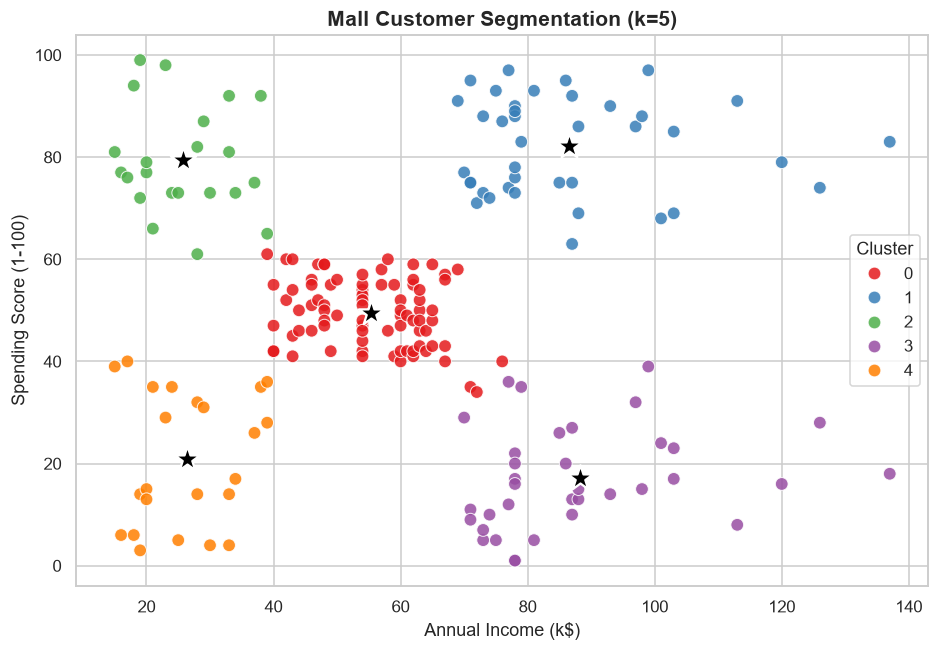

In [8]:
centroids_orig=scaler.inverse_transform(centroids_scaled)
print(centroids_orig)
df['Cluster']=labels
plt.figure(figsize=(10,6.5))
sns.scatterplot(
    data=df,x='Annual Income (k$)',y='Spending Score (1-100)',
    hue='Cluster',palette='Set1',s=70,alpha=0.85,edgecolor='w'
)
plt.scatter(
    centroids_orig[:,0],
    centroids_orig[:,1],
    color='black',marker='*',
    s=300,edgecolor='white',linewidth=1.5,label='Centroids (Cluster Centers)'
)
plt.title("Mall Customer Segmentation (k=5)",fontsize=14,fontweight='bold')


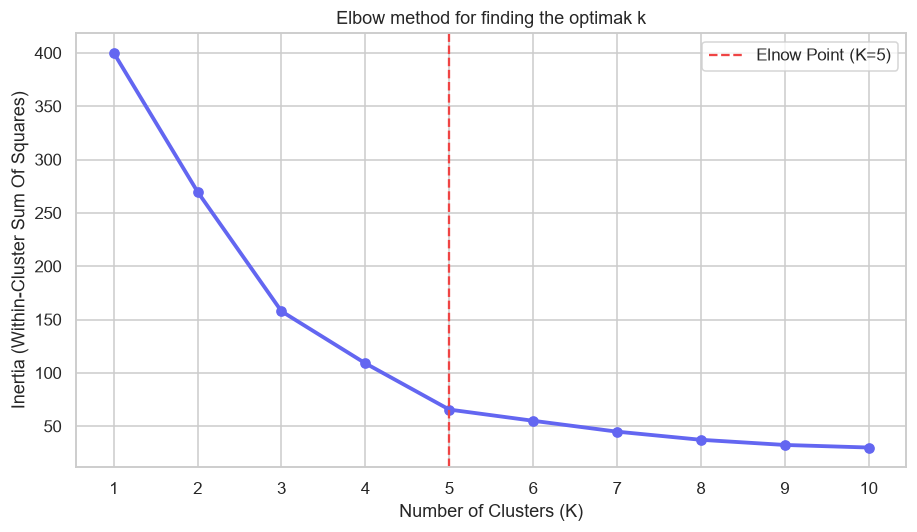

In [10]:
# 17-7-26 Day-18 (20) Friday
#choose K Elbow Method
inertias=[]
k_values=range(1,11)

for k in k_values:
    km=KMeans(n_clusters=k,init='k-means++',n_init=10,random_state=42)
    km.fit(x_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8.5,5))
plt.plot(k_values,inertias,marker='o',color='#6366f1',linewidth=2.5)
plt.title("Elbow method for finding the optimak k")
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Within-Cluster Sum Of Squares)')
plt.xticks(k_values)

plt.axvline(5,color='#ef4444',linestyle='--',label='Elnow Point (K=5)')

plt.legend()
plt.tight_layout()